# Figure 4 — large-scale virtual screening

Five panels, drawn from `raw_data/`, the Source Data submitted with the paper:

| panel | what it draws | source table |
|---|---|---|
| **4b** | wall-clock time to screen 10 million compounds, seven methods | `Fig4b_screening_wall_clock_time.csv` |
| **4g** | waterfall of the inverse rank percentile per ligand-filtered case | `Fig4g_ligand_filtered_per_case_inverse_rank_percentile.csv` |
| **4h** | top-k recall curves over the 1,000,001-compound library | `Fig4h_topk_recall_curves.csv` |
| **4i** | radar of hit rates at six screening depths | `Fig4i_per_binder_hit_indicator.csv` |
| **4j** | mean rank percentile by data-leakage filter | `Fig4j_rank_percentile_by_filter_group.csv` |

**Subset sizes are read from the data, not hard-coded.** Panel 4j splits the time-dependent
cases into `Ligand-filtered (n=13)` and `Joint-filtered (n=5)`; the wider four-way split,
including `RNA-filtered (n=12)`, is Supplementary Fig. 9b. The RNA filter drops the five 53D
complexes 9IO0/9IO1/9IOR/9IOS/9IOU, which match a training chain on both sequence and chain
structure. Because the group labels travel with the tables, the counts in the legends come out
of the CSVs rather than from a list that can go stale.

Where the SMARTBind numbers come from: `time_dependent_vs.ipynb`, screening each RNA against
the 1M-compound Chemspace library with the released 10-model ensemble, zero-shot. Its raw output
is `ranking_percentile_scores.txt` in this directory, and the last cell checks the source data
against it.

Run with `jupyter nbconvert --to notebook --execute figure4.ipynb --inplace`, or open it and
Run All. A few seconds, no GPU, no model weights.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats as sp_stats

# Locate the Source Data.  Download `raw_data` from the link named in the
# repository README and unpack it at the repository root; this walks up to find it, so
# the notebook runs from anywhere inside the checkout.
from pathlib import Path


def find_raw_data():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "raw_data"
        if candidate.is_dir():
            return candidate
    raise SystemExit(
        "\nCould not find `raw_data/`.\n\n"
        "Download the Source Data archive from the link given in the repository\n"
        "README and unpack it at the repository root, so that `raw_data/Fig2/`,\n"
        "`raw_data/Fig3/` and so on sit next to `smartbind/`.\n")


RAW = find_raw_data()
SRC = RAW / "Fig4"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

METHOD_COLORS = {
    "SMARTBind": "#64599C",
    "SMARTBind-noAug": "#9B92C4",
    "GerNA-Bind": "#AEB2D0",
    "RNAsmol": "#5B789E",
    "RNAmigos2": "#E2B668",
    "RNAmigos1": "#F4E9B3",
    "DrugBAN_RNA": "#C9A0A0",
    "GraphDTA_RNA": "#7FA99B",
    "GNINA1.3": "#A3C4BC",
    "DeepDocking": "#E8927C",
}

fig4b = pd.read_csv(SRC / "Fig4b_screening_wall_clock_time.csv")
fig4g = pd.read_csv(SRC / "Fig4g_ligand_filtered_per_case_inverse_rank_percentile.csv")
fig4h = pd.read_csv(SRC / "Fig4h_per_binder_inverse_rank_percentile.csv")
fig4h_curves = pd.read_csv(SRC / "Fig4h_topk_recall_curves.csv")
fig4i = pd.read_csv(SRC / "Fig4i_per_binder_hit_indicator.csv")
fig4i_summary = pd.read_csv(SRC / "Fig4i_summary.csv")
fig4j = pd.read_csv(SRC / "Fig4j_rank_percentile_by_filter_group.csv")
fig4j_summary = pd.read_csv(SRC / "Fig4j_summary.csv")


def mean_ci95(values):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 2:
        return (float(v.mean()) if v.size else np.nan), 0.0
    half = v.std(ddof=1) / np.sqrt(v.size) * sp_stats.t.ppf(0.975, df=v.size - 1)
    return float(v.mean()), float(half)


# subset sizes straight out of the table
for group, g in fig4j.groupby("filter_group"):
    n = g.loc[g.method == "SMARTBind"].shape[0]
    print(f"  {group:<18} {n:>2} cases")
print(f"\n  library size: {fig4h.library_size.unique()[0]:,} compounds")

  Joint-filtered      5 cases
  Ligand-filtered    13 cases

  library size: 1,000,001 compounds


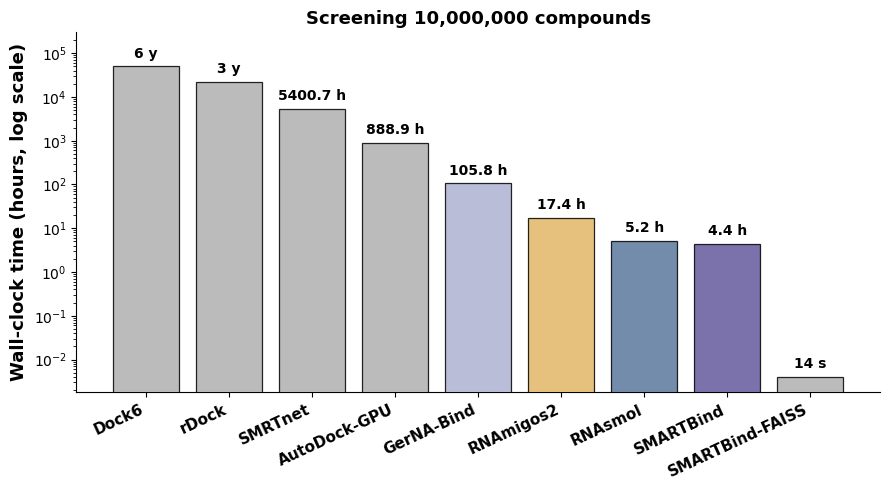

  Dock6             49972.2000 h   1 CPU core (AMD EPYC 9655P)  (n=1)
  rDock             22138.9000 h   1 CPU core (AMD EPYC 9655P)  (n=1)
  SMRTnet            5400.7000 h   1 Nvidia L4 GPU + 1 CPU core  (n=1)
  AutoDock-GPU        888.9000 h   1 Nvidia L4 GPU  (n=1)
  GerNA-Bind          105.8000 h   1 Nvidia L4 GPU + 1 CPU core  (n=1)
  RNAmigos2            17.4000 h   1 Nvidia L4 GPU + 1 CPU core  (n=1)
  RNAsmol               5.2000 h   1 Nvidia L4 GPU + 1 CPU core  (n=1)
  SMARTBind             4.4000 h   1 Nvidia L4 GPU + 1 CPU core  (n=1)
  SMARTBind-FAISS       0.0040 h   1 CPU core (FAISS search), faiss-gpu v1.7.3  (n=10)


In [2]:
# ── Fig. 4b — wall-clock time to screen 10 million compounds ─────────────────
# Log scale spans eight orders of magnitude, so the bars are labelled with the value.
order = fig4b.sort_values("wall_clock_time_hours", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
colors = [METHOD_COLORS.get(m, "#B0B0B0") for m in order.method]
bars = ax.bar(range(len(order)), order.wall_clock_time_hours, color=colors,
              edgecolor="black", linewidth=0.9, alpha=0.85, zorder=3)
ax.set_yscale("log")
for i, (_, row) in enumerate(order.iterrows()):
    hours = row.wall_clock_time_hours
    label = f"{hours / 8766:.0f} y" if hours > 8766 else (
        f"{hours:.1f} h" if hours >= 1 else f"{hours * 3600:.0f} s")
    ax.text(i, hours * 1.35, label, ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order.method, rotation=25, ha="right", fontsize=11, fontweight="bold")
ax.set_ylabel("Wall-clock time (hours, log scale)", fontsize=13, fontweight="bold")
ax.set_title(f"Screening {order.library_size.iloc[0]:,} compounds", fontsize=13, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(top=order.wall_clock_time_hours.max() * 6)
plt.tight_layout()
plt.savefig(OUT / "Fig4b_screening_time.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig4b_screening_time.png", bbox_inches="tight", dpi=600)
plt.show()

for _, r in order.iterrows():
    note = "" if pd.isna(r.get("n")) else f"  (n={int(r['n'])})"
    print(f"  {r.method:<16}{r.wall_clock_time_hours:>12.4f} h   {r.hardware}{note}")

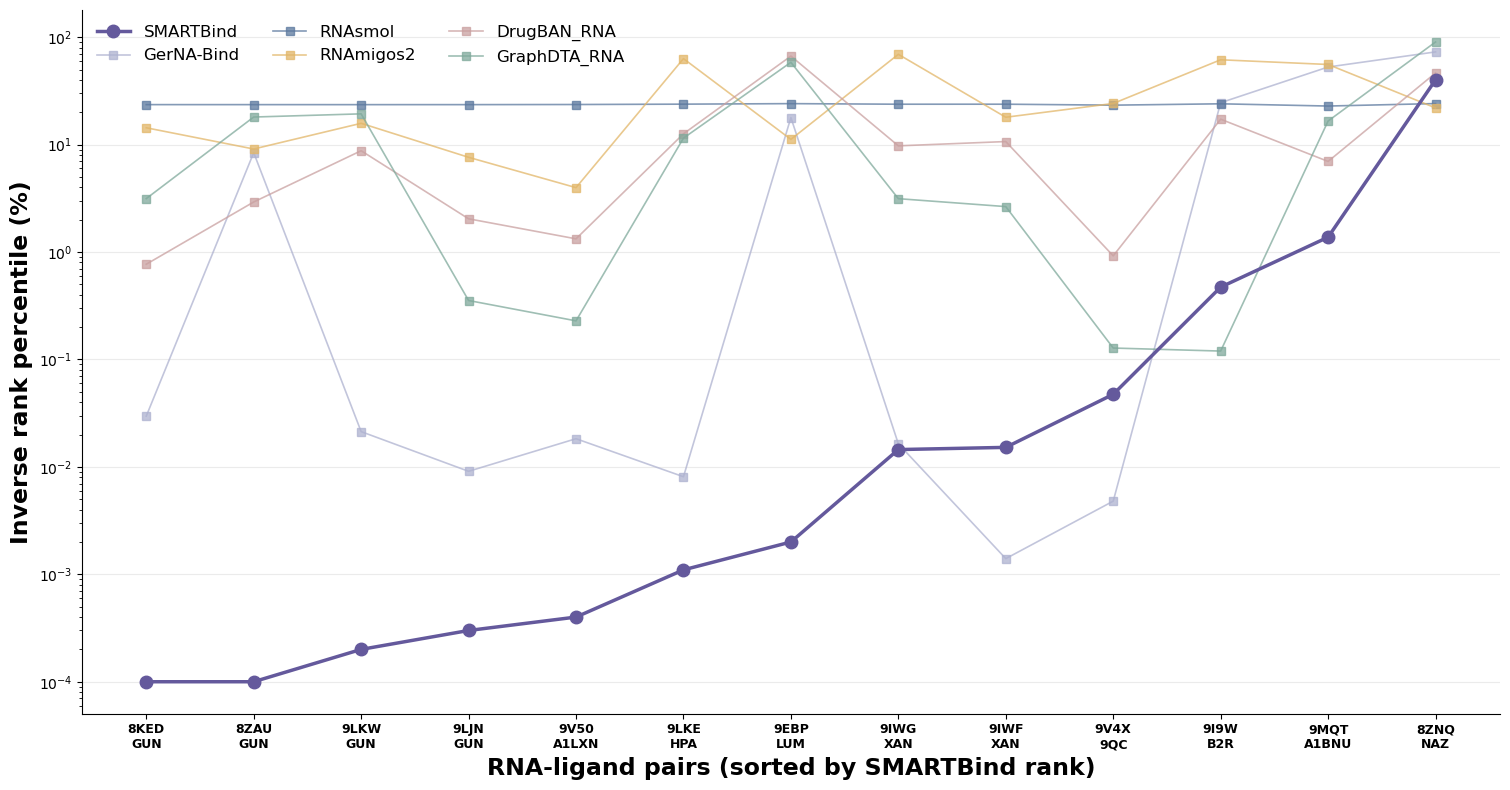

  13 ligand-filtered cases; SMARTBind median inverse rank percentile 0.0020%


In [3]:
# ── Fig. 4g — waterfall of the inverse rank percentile, ligand-filtered cases ─
# Lower is better: 1e-4 % of 1,000,001 compounds is roughly rank 1.
sb = fig4g[fig4g.method == "SMARTBind"].sort_values("inverse_rank_percentile")
case_order = sb.case.tolist()
methods = [m for m in METHOD_COLORS if m in set(fig4g.method)]

fig, ax = plt.subplots(figsize=(15.2, 8))
x = np.arange(len(case_order), dtype=float)
FLOOR = 1e-5           # the log axis is clipped here, as in the published panel
for method in methods:
    d = fig4g[fig4g.method == method].set_index("case").reindex(case_order)
    ax.plot(x, np.maximum(d.inverse_rank_percentile.values, FLOOR),
            marker="o" if method == "SMARTBind" else "s",
            markersize=9 if method == "SMARTBind" else 6,
            linewidth=2.5 if method == "SMARTBind" else 1.2,
            color=METHOD_COLORS[method], alpha=1.0 if method == "SMARTBind" else 0.75,
            label=method, zorder=6 if method == "SMARTBind" else 3)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.pdb_id}\n{r.ligand_id}" for _, r in sb.iterrows()],
                   fontsize=9, fontweight="bold")
ax.set_xlabel("RNA-ligand pairs (sorted by SMARTBind rank)", fontsize=17, fontweight="bold")
ax.set_ylabel("Inverse rank percentile (%)", fontsize=17, fontweight="bold")
ax.legend(frameon=False, fontsize=12, ncol=3, loc="upper left")
ax.grid(axis="y", alpha=0.25, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "Fig4g_waterfall.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig4g_waterfall.png", bbox_inches="tight", dpi=600)
plt.show()

print(f"  {len(case_order)} ligand-filtered cases; SMARTBind median inverse rank percentile "
      f"{sb.inverse_rank_percentile.median():.4f}%")

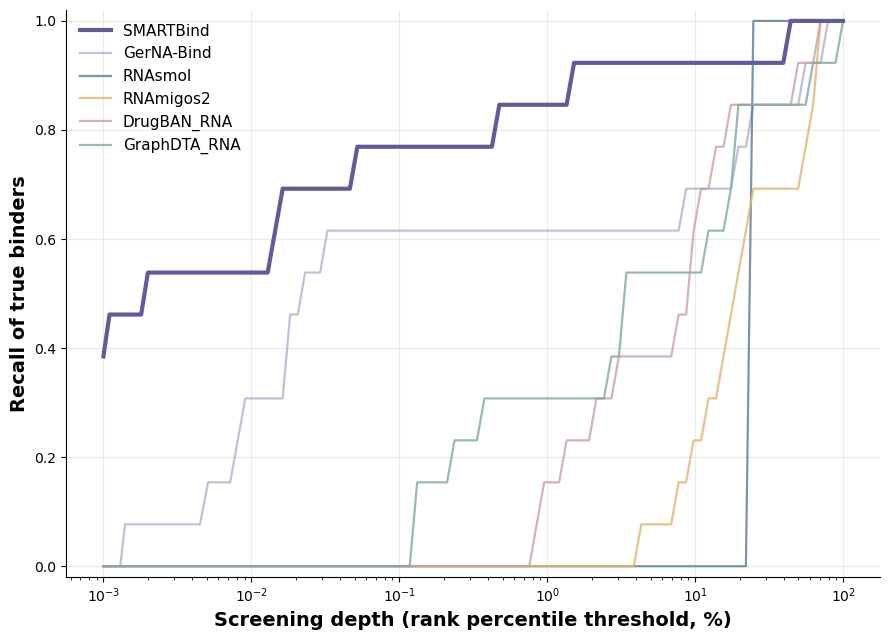

  SMARTBind       recall at 1% depth 0.8462  (11/13)
  GerNA-Bind      recall at 1% depth 0.6154  (8/13)
  RNAsmol         recall at 1% depth 0.0000  (0/13)
  RNAmigos2       recall at 1% depth 0.0000  (0/13)
  DrugBAN_RNA     recall at 1% depth 0.1538  (2/13)
  GraphDTA_RNA    recall at 1% depth 0.3077  (4/13)


In [4]:
# ── Fig. 4h — top-k recall over the 1M library ──────────────────────────────
methods = [m for m in METHOD_COLORS if m in set(fig4h_curves.method)]
fig, ax = plt.subplots(figsize=(9, 6.5))
for method in methods:
    d = fig4h_curves[fig4h_curves.method == method].sort_values("rank_percentile_threshold")
    ax.plot(d.rank_percentile_threshold, d.recall,
            linewidth=3 if method == "SMARTBind" else 1.6,
            color=METHOD_COLORS[method], label=method,
            zorder=6 if method == "SMARTBind" else 3,
            alpha=1.0 if method == "SMARTBind" else 0.8)
ax.set_xscale("log")
ax.set_xlabel("Screening depth (rank percentile threshold, %)", fontsize=14, fontweight="bold")
ax.set_ylabel("Recall of true binders", fontsize=14, fontweight="bold")
ax.set_ylim(-0.02, 1.02)
ax.legend(frameon=False, fontsize=11, loc="upper left")
ax.grid(alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "Fig4h_topk_recall.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig4h_topk_recall.png", bbox_inches="tight", dpi=600)
plt.show()

n_total = fig4h_curves.n_actives_total.iloc[0]
for method in methods:
    d = fig4h_curves[fig4h_curves.method == method]
    at1 = d.loc[(d.rank_percentile_threshold - 1.0).abs().idxmin()]
    print(f"  {method:<15} recall at 1% depth {at1.recall:.4f}  "
          f"({int(at1.n_actives_found)}/{int(n_total)})")

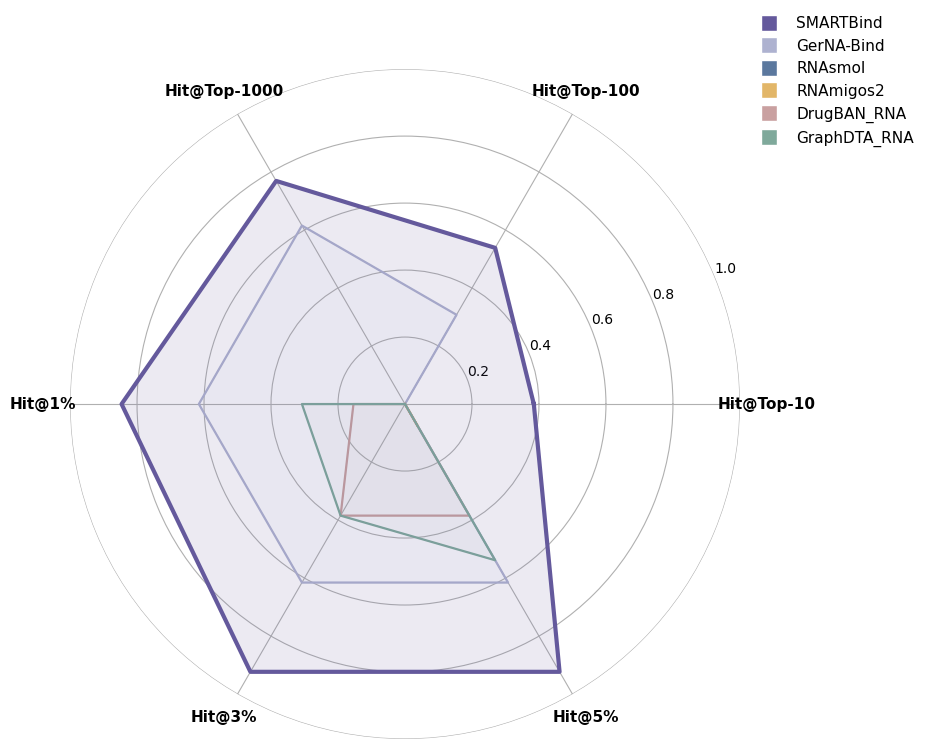

  method                Top-10     Top-100    Top-1000          1%          3%          5%
  SMARTBind              0.385       0.538       0.769       0.846       0.923       0.923
  GerNA-Bind             0.000       0.308       0.615       0.615       0.615       0.615
  RNAsmol                0.000       0.000       0.000       0.000       0.000       0.000
  RNAmigos2              0.000       0.000       0.000       0.000       0.000       0.077
  DrugBAN_RNA            0.000       0.000       0.000       0.154       0.385       0.385
  GraphDTA_RNA           0.000       0.000       0.000       0.308       0.385       0.538


In [5]:
# ── Fig. 4i — hit rate at six screening depths (radar) ──────────────────────
METRICS = ["Hit@Top-10", "Hit@Top-100", "Hit@Top-1000", "Hit@1%", "Hit@3%", "Hit@5%"]
methods = [m for m in METHOD_COLORS if m in set(fig4i.method)]

rate = {m: [fig4i.loc[(fig4i.method == m) & (fig4i.metric == k), "is_hit"].mean()
            for k in METRICS] for m in methods}

angles = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(9, 7.5), subplot_kw=dict(polar=True))
for method in methods:
    vals = rate[method] + rate[method][:1]
    lead = method == "SMARTBind"
    ax.plot(angles, vals, linewidth=3 if lead else 1.6, color=METHOD_COLORS[method],
            zorder=6 if lead else 3)
    ax.fill(angles, vals, color=METHOD_COLORS[method], alpha=0.12 if lead else 0.04,
            zorder=6 if lead else 3)
ax.set_xticks(angles[:-1])
ax.set_xticklabels([])
for angle, name in zip(angles[:-1], METRICS):
    ax.text(angle, 1.08, name, ha="center", va="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.spines["polar"].set_visible(False)
ax.legend(handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=METHOD_COLORS[m],
                          markersize=11, label=m) for m in methods],
          loc="upper right", bbox_to_anchor=(1.28, 1.10), frameon=False, fontsize=11)
plt.tight_layout()
plt.savefig(OUT / "Fig4i_hit_rate_radar.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig4i_hit_rate_radar.png", bbox_inches="tight", dpi=600)
plt.show()

print(f"  {'method':<16}" + "".join(f"{k.replace('Hit@',''):>12}" for k in METRICS))
for m in methods:
    print(f"  {m:<16}" + "".join(f"{v:>12.3f}" for v in rate[m]))

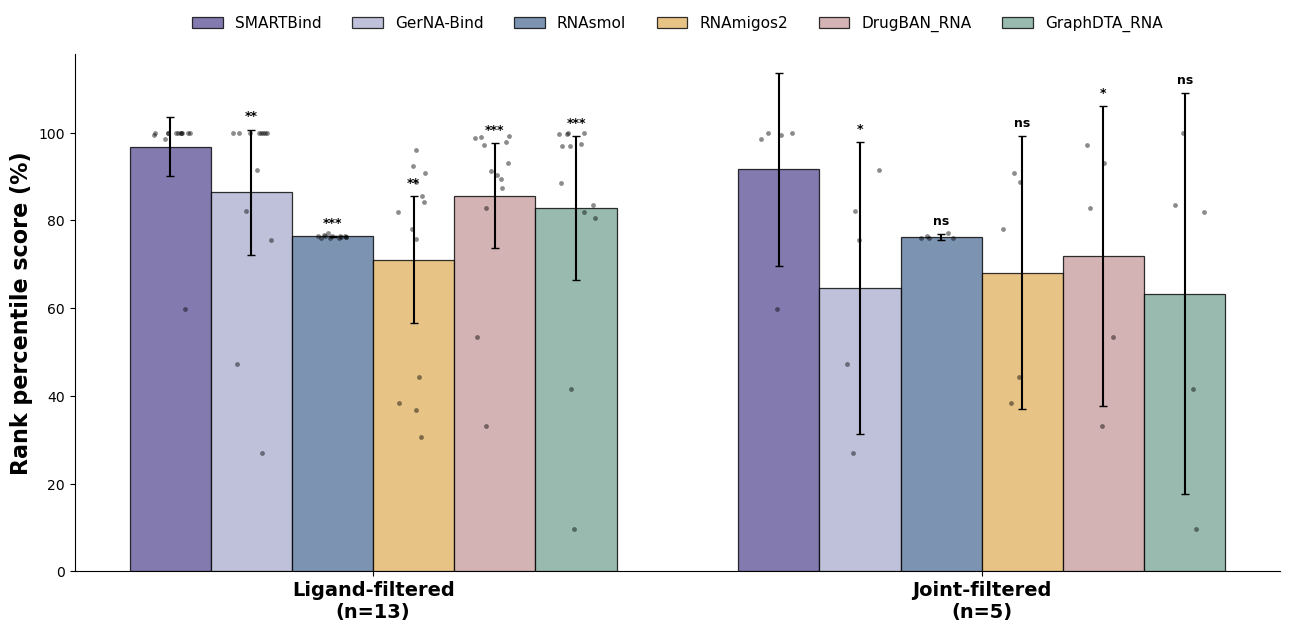

  Ligand-filtered    (n=13)  best SMARTBind 0.968 ± 0.111   second GerNA-Bind 0.864 ± 0.237
  Joint-filtered     (n=5)  best SMARTBind 0.916 ± 0.177   second RNAsmol 0.763 ± 0.005


In [6]:
# ── Fig. 4j — mean rank percentile by data-leakage filter ───────────────────
GROUPS = ["Ligand-filtered", "Joint-filtered"]
methods = [m for m in METHOD_COLORS if m in set(fig4j.method)]

fig, ax = plt.subplots(figsize=(13, 6.4))
width = 0.8 / len(methods)
x = np.arange(len(GROUPS), dtype=float)
rng = np.random.default_rng(42)

for j, method in enumerate(methods):
    offset = width * (j - (len(methods) - 1) / 2)
    for i, group in enumerate(GROUPS):
        vals = fig4j.loc[(fig4j.method == method) & (fig4j.filter_group == group),
                         "rank_percentile_score"].values
        mean, ci = mean_ci95(vals)
        ax.bar(x[i] + offset, mean, width, yerr=ci, color=METHOD_COLORS[method], alpha=0.8,
               capsize=3, edgecolor="black", linewidth=0.9, zorder=3,
               label=method if i == 0 else None)
        jitter = rng.uniform(-width * 0.25, width * 0.25, vals.size)
        ax.scatter(np.full(vals.size, x[i] + offset) + jitter, vals,
                   color="black", s=12, alpha=0.45, zorder=10, linewidths=0)

# the significance labels the panel prints, taken from the shipped summary
for i, group in enumerate(GROUPS):
    for j, method in enumerate(methods):
        row = fig4j_summary[(fig4j_summary.filter_group == group)
                            & (fig4j_summary.method == method)]
        if row.empty or pd.isna(row.significance_label.iloc[0]):
            continue
        offset = width * (j - (len(methods) - 1) / 2)
        top = row.plotted_centre_mean_rank_percentile_score.iloc[0] + row.ci95_half_width.iloc[0]
        ax.text(x[i] + offset, top + 1.5, str(row.significance_label.iloc[0]),
                ha="center", va="bottom", fontsize=9, fontweight="bold")

n_by_group = {g: int(fig4j_summary.loc[fig4j_summary.filter_group == g, "n"].iloc[0])
              for g in GROUPS}
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={n_by_group[g]})" for g in GROUPS], fontsize=14, fontweight="bold")
ax.set_ylabel("Rank percentile score (%)", fontsize=16, fontweight="bold")
ax.set_ylim(0, 118)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(frameon=False, fontsize=11, ncol=len(methods), loc="upper center",
          bbox_to_anchor=(0.5, 1.10))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "Fig4j_performance_by_filter_groups.pdf", bbox_inches="tight", dpi=300)
plt.savefig(OUT / "Fig4j_performance_by_filter_groups.png", bbox_inches="tight", dpi=600)
plt.show()

for group in GROUPS:
    g = fig4j_summary[fig4j_summary.filter_group == group].sort_values(
        "plotted_centre_mean_rank_percentile_score", ascending=False)
    best, second = g.iloc[0], g.iloc[1]
    print(f"  {group:<18} (n={n_by_group[group]})  best {best.method} "
          f"{best.plotted_centre_mean_rank_percentile_score / 100:.3f} ± {best.sd / 100:.3f}"
          f"   second {second.method} "
          f"{second.plotted_centre_mean_rank_percentile_score / 100:.3f} ± {second.sd / 100:.3f}")

In [7]:
# ── Self-check: plotted values vs the shipped summaries, and vs the raw screen ──
failures = []
checks = 0


def compare(label, got, want, tol=5e-4):
    global checks
    checks += 1
    if abs(float(got) - float(want)) > tol:
        failures.append(f"{label}: recomputed {float(got):.6f} vs shipped {float(want):.6f}")
        return False
    return True


print("Fig. 4i — hit rates")
for _, row in fig4i_summary.iterrows():
    v = fig4i.loc[(fig4i.method == row.method) & (fig4i.metric == row.metric), "is_hit"]
    compare(f"4i {row.method}/{row.metric} n", len(v), row.n, 0)
    compare(f"4i {row.method}/{row.metric} rate", v.mean(), row.plotted_hit_rate)
    compare(f"4i {row.method}/{row.metric} hits", v.sum(), row.n_hits, 0)
print(f"  {len(fig4i_summary)} radar vertices   {'ok' if not failures else 'MISMATCH'}")

print("\nFig. 4j — bar heights, error bars and subset sizes")
for _, row in fig4j_summary.iterrows():
    v = fig4j.loc[(fig4j.method == row.method)
                  & (fig4j.filter_group == row.filter_group), "rank_percentile_score"].values
    mean, ci = mean_ci95(v)
    compare(f"4j {row.filter_group}/{row.method} n", len(v), row.n, 0)
    compare(f"4j {row.filter_group}/{row.method} mean",
            mean, row.plotted_centre_mean_rank_percentile_score, 5e-3)
    compare(f"4j {row.filter_group}/{row.method} sd", v.std(ddof=1), row.sd, 5e-3)
    compare(f"4j {row.filter_group}/{row.method} ci95", ci, row.ci95_half_width, 5e-3)
for group, n in (("Ligand-filtered", 13), ("Joint-filtered", 5)):
    got = int(fig4j_summary.loc[fig4j_summary.filter_group == group, "n"].iloc[0])
    if got != n:
        failures.append(f"subset {group}: {got} cases, expected {n}")
    print(f"  {group:<18} n={got}  {'ok' if got == n else 'MISMATCH'}")

# ── and against the raw virtual-screening output that produced them ──────────
print("\nSMARTBind rows vs ranking_percentile_scores.txt (the raw 1M screen)")
raw_path = Path("ranking_percentile_scores.txt")
if raw_path.exists():
    screen = {m.group(1): float(m.group(4)) for m in re.finditer(
        r"For (\S+), the rank is (\d+) out of (\d+)\s*\nRank percentage: ([0-9.eE+-]+)%",
        raw_path.read_text())}
    for label, table, col in (("Fig4g", fig4g, "inverse_rank_percentile"),
                              ("Fig4h", fig4h, "inverse_rank_percentile"),
                              ("Fig4j", fig4j, "inverse_rank_percentile")):
        d = table[table.method == "SMARTBind"]
        dev = [abs(screen[f"{r.pdb_id}_{r.ligand_id}"] - r[col]) for _, r in d.iterrows()
               if f"{r.pdb_id}_{r.ligand_id}" in screen]
        checks += len(dev)
        worst = max(dev) if dev else 0.0
        if worst > 1e-3:
            failures.append(f"{label}: max deviation from the raw screen {worst:.2e}")
        print(f"  {label:<8} {len(dev):>3} cases matched   max |Δ| {worst:.1e}"
              f"   {'ok' if worst <= 1e-3 else 'MISMATCH'}")
else:
    print("  ranking_percentile_scores.txt not found — skipping this check")

print()
if failures:
    for f in failures:
        print("  " + f)
    raise AssertionError(f"{len(failures)} value(s) do not reproduce")
print(f"PASS — every plotted value reproduces the shipped summary tables and the raw "
      f"screening output ({checks} checks)")

Fig. 4i — hit rates
  36 radar vertices   ok

Fig. 4j — bar heights, error bars and subset sizes
  Ligand-filtered    n=13  ok
  Joint-filtered     n=5  ok

SMARTBind rows vs ranking_percentile_scores.txt (the raw 1M screen)
  Fig4g     13 cases matched   max |Δ| 4.0e-05   ok
  Fig4h     13 cases matched   max |Δ| 4.0e-05   ok
  Fig4j     18 cases matched   max |Δ| 4.0e-05   ok

PASS — every plotted value reproduces the shipped summary tables and the raw screening output (200 checks)
